In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [16]:
import os
os.environ["OMP_NUM_THREADS"]="1"
from sklearn.cluster import KMeans

In [17]:
import os
print(os.listdir('/content'))

['.config', 'Mall_Customers.csv', 'sample_data']


In [18]:
df=pd.read_csv('/content/Mall_Customers.csv')
print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


In [19]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [20]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [21]:
print("number of rows:",df.shape[0])
print("number of columns:",df.shape[1])

number of rows: 200
number of columns: 5


In [22]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [23]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [24]:
print(df.describe())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [25]:
print(df["Gender"].value_counts())

Gender
Female    112
Male       88
Name: count, dtype: int64


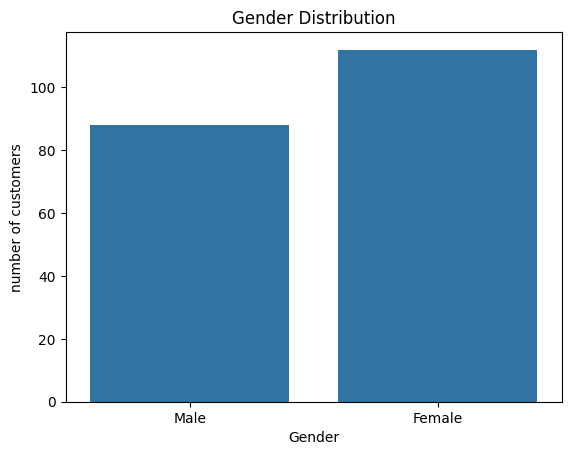

In [26]:
sns.countplot(x="Gender",data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("number of customers")
plt.show()

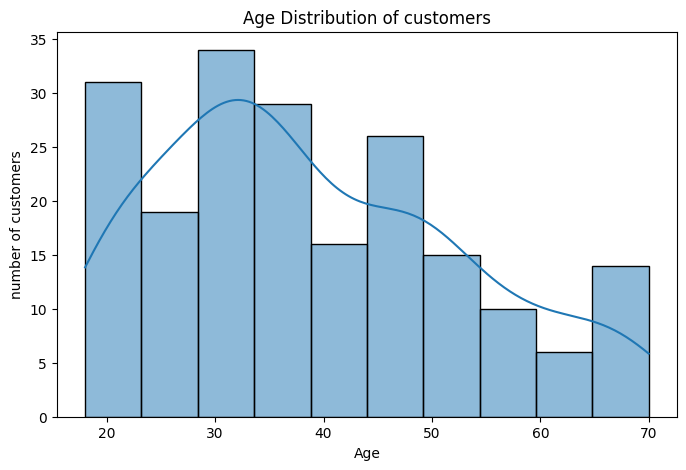

In [27]:
plt.figure(figsize=(8,5))
sns.histplot(df["Age"],bins=10,kde=True)
plt.title("Age Distribution of customers")
plt.xlabel("Age")
plt.ylabel("number of customers")
plt.show()

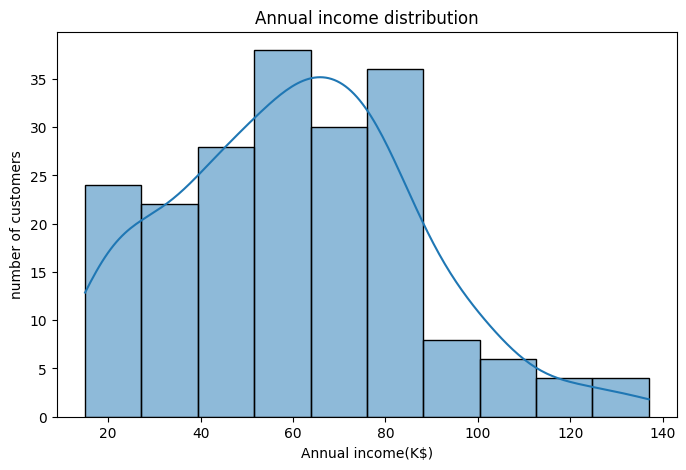

In [28]:
plt.figure(figsize=(8,5))
sns.histplot(df["Annual Income (k$)"],bins=10,kde=True)
plt.title("Annual income distribution")
plt.xlabel("Annual income(K$)")
plt.ylabel("number of customers")
plt.show()

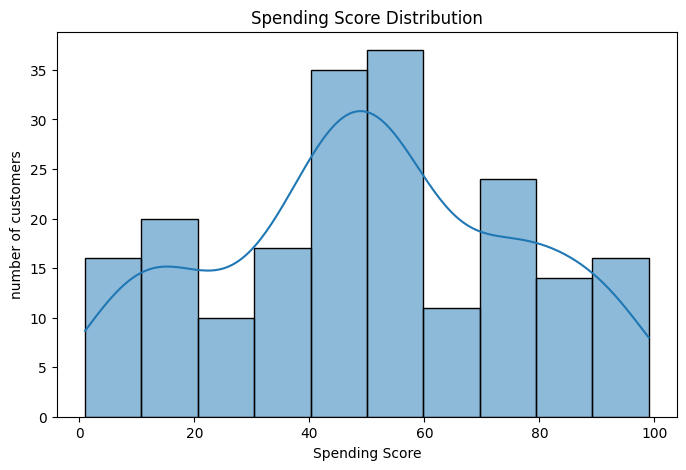

In [29]:
plt.figure(figsize=(8,5))
sns.histplot(df["Spending Score (1-100)"],bins=10,kde=True)
plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("number of customers")
plt.show()

In [30]:
x=df[["Annual Income (k$)","Spending Score (1-100)"]]

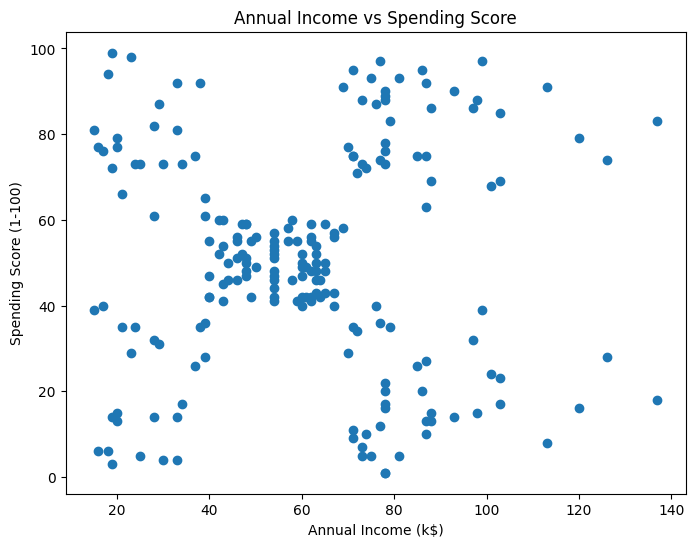

In [31]:
plt.figure(figsize=(8,6))
plt.scatter(x["Annual Income (k$)"],x["Spending Score (1-100)"])
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()



In [32]:
inertia=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(x)
    inertia.append(kmeans.inertia_)

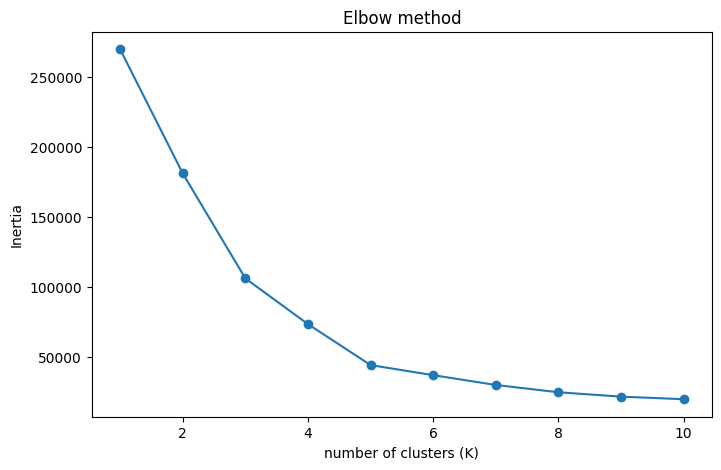

In [33]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11),inertia,marker='o')
plt.title("Elbow method")
plt.xlabel("number of clusters (K)")
plt.ylabel("Inertia")
plt.show()

In [34]:
kmeans=KMeans(n_clusters=5,random_state=42,n_init=10)

In [35]:
kmeans.fit(x)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [36]:
df["Cluster"]=kmeans.labels_

In [37]:
print(kmeans.cluster_centers_)

[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


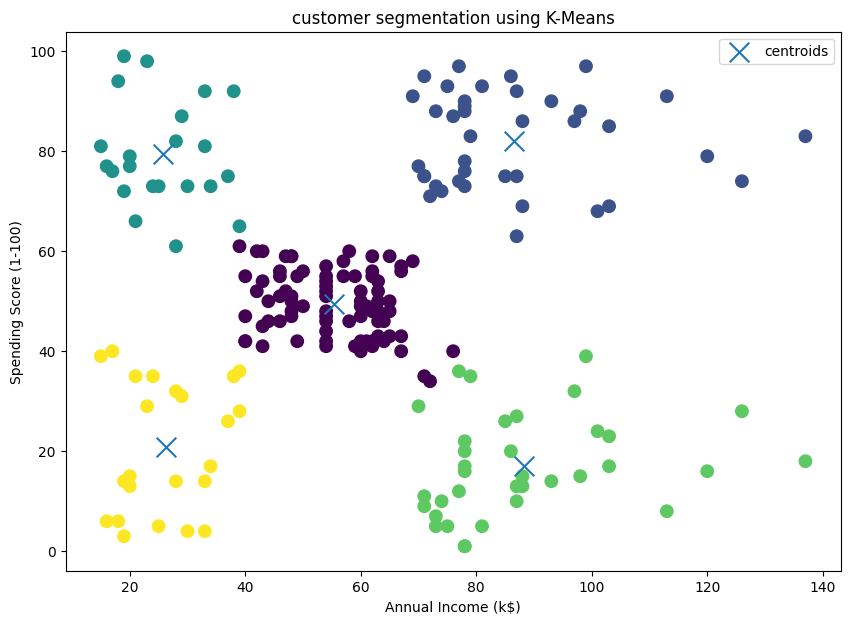

In [38]:
plt.figure(figsize=(10,7))
plt.scatter(x["Annual Income (k$)"],x["Spending Score (1-100)"],c=df["Cluster"],s=80)
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=200,marker="x",label="centroids")
plt.title("customer segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

In [39]:
cluster_summary=df.groupby("Cluster")[["Age","Annual Income (k$)","Spending Score (1-100)"]].mean()
print(cluster_summary)

               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        42.716049           55.296296               49.518519
1        32.692308           86.538462               82.128205
2        25.272727           25.727273               79.363636
3        41.114286           88.200000               17.114286
4        45.217391           26.304348               20.913043


In [40]:
def segment_customer(row):
    income=row["Annual Income (k$)"]
    spending=row["Spending Score (1-100)"]
    if income >=70 and spending >=60:
        return "premium Customers"
    elif income >=70 and spending < 60:
        return "Careful Customers"
    elif income <40 and spending >=60:
        return "High Spending Low Income"
    elif income <40 and spending <60:
        return "Low value Customer"
    else:
        return "Average customers"



In [41]:
df["Customer Segment"]=df.apply(segment_customer,axis=1)


In [42]:
print(df[["CustomerID","Age","Annual Income (k$)","Spending Score (1-100)","Customer Segment"]])

     CustomerID  Age  Annual Income (k$)  Spending Score (1-100)  \
0             1   19                  15                      39   
1             2   21                  15                      81   
2             3   20                  16                       6   
3             4   23                  16                      77   
4             5   31                  17                      40   
..          ...  ...                 ...                     ...   
195         196   35                 120                      79   
196         197   45                 126                      28   
197         198   32                 126                      74   
198         199   32                 137                      18   
199         200   30                 137                      83   

             Customer Segment  
0          Low value Customer  
1    High Spending Low Income  
2          Low value Customer  
3    High Spending Low Income  
4          Low value Cu

In [43]:
print(df["Customer Segment"].value_counts())

Customer Segment
Average customers           78
premium Customers           38
Careful Customers           38
Low value Customer          23
High Spending Low Income    23
Name: count, dtype: int64


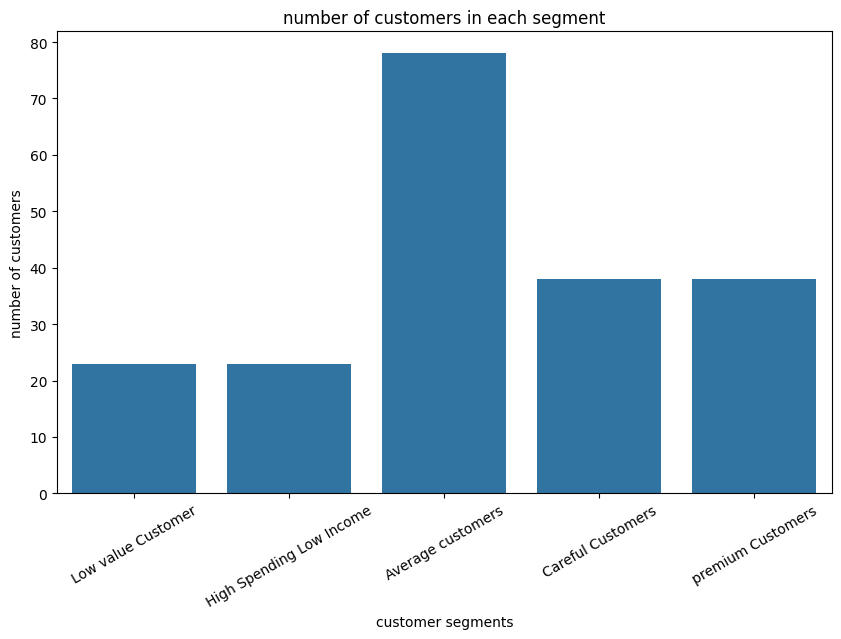

In [44]:
plt.figure(figsize=(10,6))
sns.countplot(x="Customer Segment",data=df)
plt.title("number of customers in each segment")
plt.xlabel("customer segments")
plt.ylabel("number of customers")
plt.xticks(rotation=30)
plt.show()

In [45]:
df.to_csv("customer_segmentation_result.csv",index=False)
print("customer segmentation results saved successfully")

customer segmentation results saved successfully


In [46]:
sample_customer=[[80,85]]
prediction=kmeans.predict(sample_customer)
print("prediction cluster:",prediction[0])

prediction cluster: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
